# CLIP Playground (pretrained OpenAI CLIP)

This notebook lets you try a pretrained CLIP model end to end:

1. Zero-shot classification on any image (URL or upload) with prompt ensembling
2. Image-text similarity matrix
3. Zero-shot benchmark on CIFAR-10
4. Few-shot linear probe (1 to 16 shots per class) vs zero-shot
5. Text-to-image retrieval
6. Run zero-shot and few-shot on **your own dataset** (class-per-folder)

**Runtime:** `Runtime > Change runtime type > T4 GPU` is recommended (CPU works but is slow).

#### Helpful Youtube video: https://www.youtube.com/watch?v=KcSXcpluDe4&t=10s

## 1. Setup

In [1]:
!pip -q install transformers scikit-learn

In [2]:
import os, time
from io import BytesIO

import numpy as np
import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Load the model

Pick a checkpoint:

| MODEL_ID | Notes |
|---|---|
| `openai/clip-vit-base-patch32` | Fastest, ~150M params |
| `openai/clip-vit-base-patch16` | Better accuracy, slower |
| `openai/clip-vit-large-patch14` | Best of the three, needs GPU |

In [3]:
MODEL_ID = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(MODEL_ID).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_ID)
print(f"Loaded {MODEL_ID}: {sum(p.numel() for p in model.parameters())/1e6:.1f}M params")
print("Embedding dim:", model.config.projection_dim, "| logit scale:", model.logit_scale.exp().item())

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loaded openai/clip-vit-base-patch32: 151.3M params
Embedding dim: 512 | logit scale: 100.0


### Helper functions (encode images / texts, load images)

In [4]:
def _as_tensor(out, key):
    """get_*_features returns a tensor in transformers 4.x and an output object in newer versions."""
    if torch.is_tensor(out):
        return out
    for k in (key, "pooler_output"):
        v = getattr(out, k, None)
        if v is not None:
            return v
    raise TypeError(f"Unexpected output type: {type(out)}")

@torch.no_grad()
def encode_images(images, batch_size=64):
    """List of PIL images -> L2-normalised embeddings [N, D]."""
    feats = []
    for i in range(0, len(images), batch_size):
        inputs = processor(images=images[i:i + batch_size], return_tensors="pt").to(device)
        f = _as_tensor(model.get_image_features(**inputs), "image_embeds")
        feats.append(f / f.norm(dim=-1, keepdim=True))
    return torch.cat(feats)

@torch.no_grad()
def encode_texts(texts, batch_size=256):
    """List of strings -> L2-normalised embeddings [N, D]."""
    feats = []
    for i in range(0, len(texts), batch_size):
        inputs = processor(text=texts[i:i + batch_size], return_tensors="pt",
                           padding=True, truncation=True).to(device)
        f = _as_tensor(model.get_text_features(**inputs), "text_embeds")
        feats.append(f / f.norm(dim=-1, keepdim=True))
    return torch.cat(feats)

def load_image(src):
    """Load a PIL image from a URL or a local path."""
    if src.startswith("http"):
        r = requests.get(src, timeout=30)
        r.raise_for_status()
        return Image.open(BytesIO(r.content)).convert("RGB")
    return Image.open(src).convert("RGB")

## 3. Zero-shot classification

CLIP turns each class name into a text embedding ("a photo of a {class}") and picks the class whose
embedding is closest to the image embedding. Averaging over several prompt templates
(**prompt ensembling**) usually adds a point or two of accuracy.

In [5]:
TEMPLATES = [
    "a photo of a {}.",
    "a blurry photo of a {}.",
    "a close-up photo of a {}.",
    "a photo of the large {}.",
    "a photo of the small {}.",
    "a low resolution photo of a {}.",
    "a cropped photo of a {}.",
    "a bright photo of a {}.",
]

@torch.no_grad()
def build_zeroshot_weights(classnames, templates=TEMPLATES):
    """One averaged, normalised text embedding per class -> [C, D]."""
    weights = []
    for c in classnames:
        t = encode_texts([tpl.format(c) for tpl in templates])
        w = t.mean(0)
        weights.append(w / w.norm())
    return torch.stack(weights)

@torch.no_grad()
def zero_shot(image, classnames, templates=TEMPLATES, show=True, topk=5):
    W = build_zeroshot_weights(classnames, templates)
    img = encode_images([image])
    probs = (model.logit_scale.exp() * img @ W.T).softmax(-1)[0].cpu().numpy()
    order = probs.argsort()[::-1][:topk]
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})
        ax[0].imshow(image); ax[0].axis("off")
        ax[1].barh([classnames[i] for i in order][::-1], probs[order][::-1], color="#4c72b0")
        ax[1].set_xlim(0, 1); ax[1].set_xlabel("probability")
        ax[1].set_title("Zero-shot prediction")
        plt.tight_layout(); plt.show()
    return {classnames[i]: float(probs[i]) for i in order}

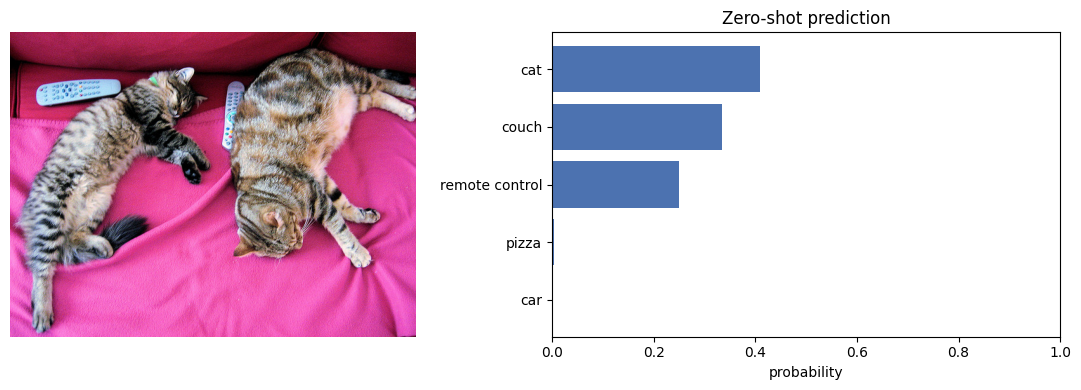

{'cat': 0.4090803265571594,
 'couch': 0.33542823791503906,
 'remote control': 0.24977120757102966,
 'pizza': 0.003428287338465452,
 'car': 0.0011314157163724303}

In [6]:
img = load_image("http://images.cocodataset.org/val2017/000000039769.jpg")
labels = ["cat", "dog", "remote control", "couch", "car", "bird", "pizza"]
zero_shot(img, labels)

### Try your own image

Edit `MY_URL` and `MY_LABELS`, or run the upload cell below. Labels can be any free text,
for example `"a torn seam on a shirt"` vs `"a clean seam on a shirt"`.

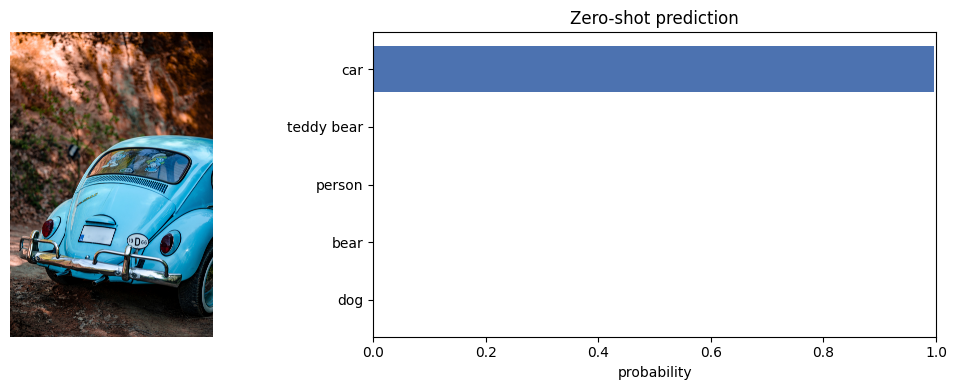

{'car': 0.995633065700531,
 'teddy bear': 0.0017491717590019107,
 'person': 0.0011941177072003484,
 'bear': 0.0010249876650050282,
 'dog': 0.00036049619666300714}

In [7]:
MY_URL = "https://images.pexels.com/photos/31732759/pexels-photo-31732759.jpeg?cs=srgb&dl=pexels-shndgd-31732759.jpg&fm=jpg"
MY_LABELS = ["bear", "dog", "teddy bear", "wolf", "person", "car"]
zero_shot(load_image(MY_URL), MY_LABELS)

In [ ]:
# Upload one or more images from your computer
try:
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        print(name)
        zero_shot(load_image(name), MY_LABELS)
except ImportError:
    print("Not running in Colab: set a local path and call zero_shot(load_image(path), MY_LABELS).")

## 4. Image-text similarity matrix

Cosine similarity between every image and every caption. The diagonal should light up.

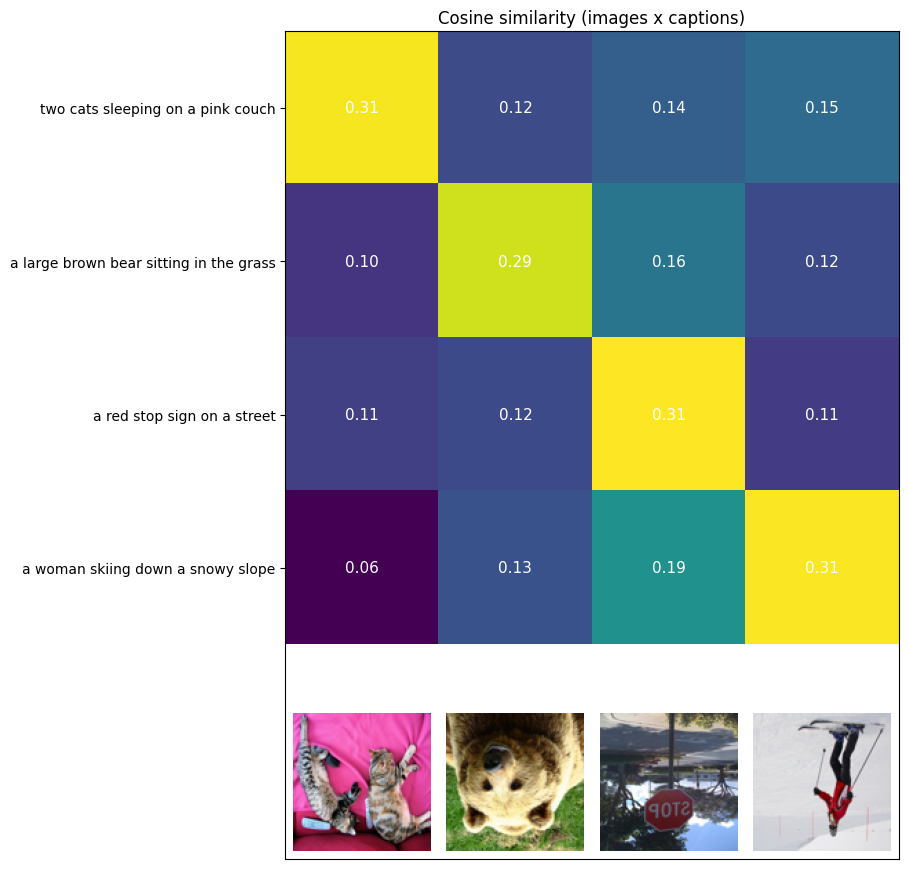

In [8]:
pairs = {
    "http://images.cocodataset.org/val2017/000000039769.jpg": "two cats sleeping on a pink couch",
    "http://images.cocodataset.org/val2017/000000000285.jpg": "a large brown bear sitting in the grass",
    "http://images.cocodataset.org/val2017/000000000724.jpg": "a red stop sign on a street",
    "http://images.cocodataset.org/val2017/000000000785.jpg": "a woman skiing down a snowy slope",
}
imgs, caps = [], []
for url, cap in pairs.items():
    try:
        imgs.append(load_image(url)); caps.append(cap)
    except Exception as e:
        print("skip", url, e)

sim = (encode_images(imgs) @ encode_texts(caps).T).cpu().numpy()

fig, ax = plt.subplots(figsize=(2.2 * len(imgs) + 4, 2.2 * len(imgs)))
ax.imshow(sim, cmap="viridis")
ax.set_yticks(range(len(caps))); ax.set_yticklabels(caps)
ax.set_xticks([])
for j, im in enumerate(imgs):
    ax.imshow(im.resize((100, 100)), extent=(j - 0.45, j + 0.45, len(caps) - 0.05, len(caps) + 0.85))
for i in range(sim.shape[0]):
    for j in range(sim.shape[1]):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", color="white", fontsize=11)
ax.set_xlim(-0.5, len(imgs) - 0.5); ax.set_ylim(len(caps) + 0.9, -0.5)
ax.set_title("Cosine similarity (images x captions)")
plt.tight_layout(); plt.show()

## 5. Zero-shot benchmark on CIFAR-10

Encodes a subset of the CIFAR-10 test set once and caches the features (they are reused in
sections 6 and 7). Expect roughly 85 to 90% with ViT-B/32.

In [9]:
from torchvision.datasets import CIFAR10

N_TEST = 2000          # raise to 10000 for the full test set
SEED = 0
rng = np.random.default_rng(SEED)

cifar_test = CIFAR10(root="/content/data", train=False, download=True)
cifar_train = CIFAR10(root="/content/data", train=True, download=True)
CLASSES = cifar_test.classes

test_idx = rng.choice(len(cifar_test), N_TEST, replace=False)
test_imgs = [cifar_test[i][0] for i in test_idx]
test_labels = np.array([cifar_test[i][1] for i in test_idx])

t0 = time.time()
test_feats = encode_images(test_imgs)
print(f"Encoded {N_TEST} test images in {time.time() - t0:.1f}s")

100%|██████████| 170M/170M [01:28<00:00, 1.92MB/s]


Encoded 2000 test images in 5.6s


In [10]:
def zeroshot_accuracy(feats, labels, classnames, templates=TEMPLATES):
    W = build_zeroshot_weights(classnames, templates)
    preds = (feats @ W.T).argmax(-1).cpu().numpy()
    return (preds == labels).mean(), preds

acc_single, _ = zeroshot_accuracy(test_feats, test_labels, CLASSES, ["a photo of a {}."])
acc_ens, zs_preds = zeroshot_accuracy(test_feats, test_labels, CLASSES)
print(f"Zero-shot, single prompt : {acc_single * 100:.2f}%")
print(f"Zero-shot, {len(TEMPLATES)} prompts    : {acc_ens * 100:.2f}%")

Zero-shot, single prompt : 88.20%
Zero-shot, 8 prompts    : 88.70%


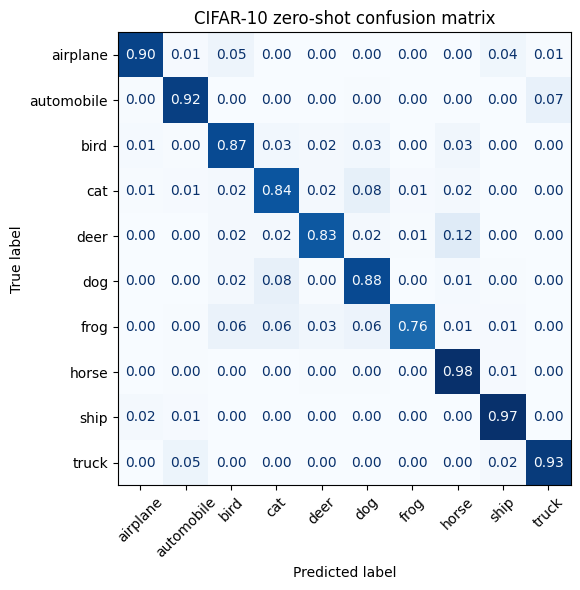

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(test_labels, zs_preds, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f",
                                                       xticks_rotation=45, colorbar=False)
ax.set_title("CIFAR-10 zero-shot confusion matrix")
plt.tight_layout(); plt.show()

## 6. Few-shot linear probe

Freeze CLIP, take *k* labelled images per class, and fit logistic regression on the image
embeddings. This is the standard "linear probe" baseline from the CLIP paper and a useful
reference point for few-shot work. Note how 1-shot can be *worse* than zero-shot.

In [12]:
from sklearn.linear_model import LogisticRegression

SHOTS = [1, 2, 4, 8, 16]
N_TRIALS = 3   # average over random draws of the support set

train_targets = np.array(cifar_train.targets)
X_test = test_feats.cpu().numpy()

def sample_support(k, seed):
    r = np.random.default_rng(seed)
    idx = np.concatenate([r.choice(np.where(train_targets == c)[0], k, replace=False)
                          for c in range(len(CLASSES))])
    return idx

results = {}
for k in SHOTS:
    accs = []
    for t in range(N_TRIALS):
        idx = sample_support(k, seed=100 * k + t)
        X_tr = encode_images([cifar_train[i][0] for i in idx]).cpu().numpy()
        y_tr = train_targets[idx]
        clf = LogisticRegression(C=0.316, max_iter=2000)
        clf.fit(X_tr, y_tr)
        accs.append(clf.score(X_test, test_labels))
    results[k] = (np.mean(accs), np.std(accs))
    print(f"{k:>2}-shot: {results[k][0] * 100:.2f}% +/- {results[k][1] * 100:.2f}")

 1-shot: 62.75% +/- 6.90
 2-shot: 75.22% +/- 3.41
 4-shot: 74.50% +/- 1.66
 8-shot: 85.95% +/- 0.66
16-shot: 88.20% +/- 0.35


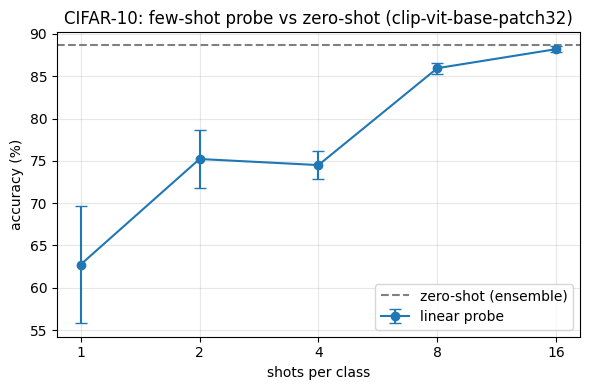

In [13]:
ks = list(results)
means = [results[k][0] * 100 for k in ks]
stds = [results[k][1] * 100 for k in ks]
plt.figure(figsize=(6, 4))
plt.errorbar(ks, means, yerr=stds, marker="o", capsize=4, label="linear probe")
plt.axhline(acc_ens * 100, color="gray", ls="--", label="zero-shot (ensemble)")
plt.xscale("log", base=2); plt.xticks(ks, ks)
plt.xlabel("shots per class"); plt.ylabel("accuracy (%)")
plt.title(f"CIFAR-10: few-shot probe vs zero-shot ({MODEL_ID.split('/')[-1]})")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 7. Text-to-image retrieval

Search the encoded CIFAR-10 test images with a free-text query.

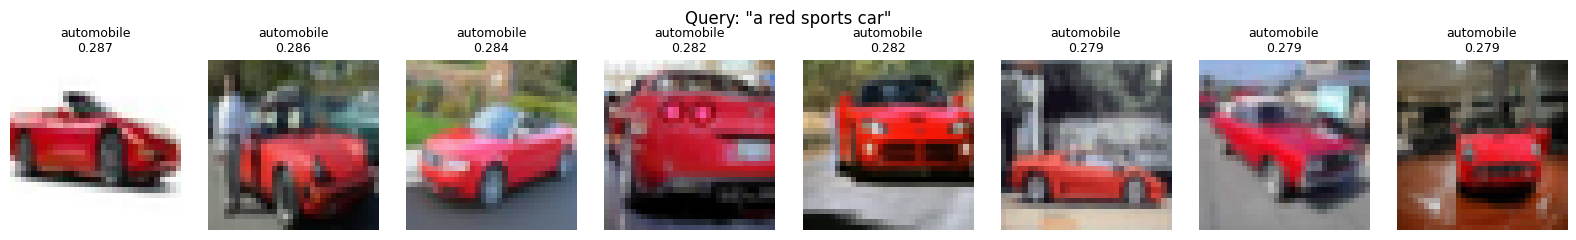

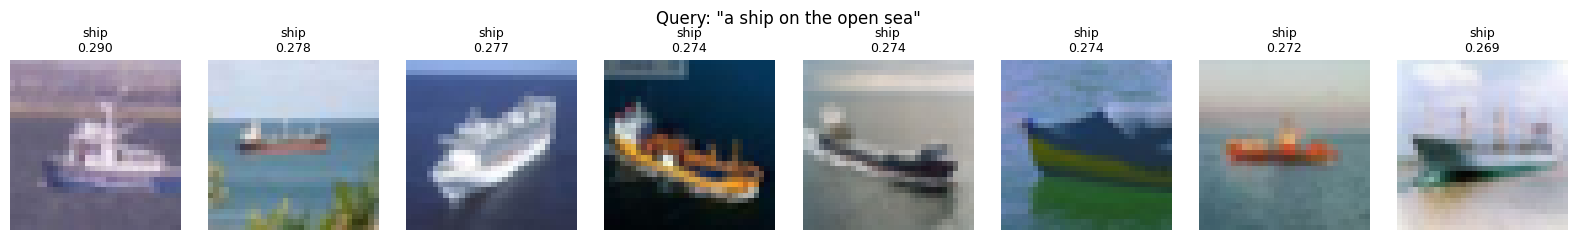

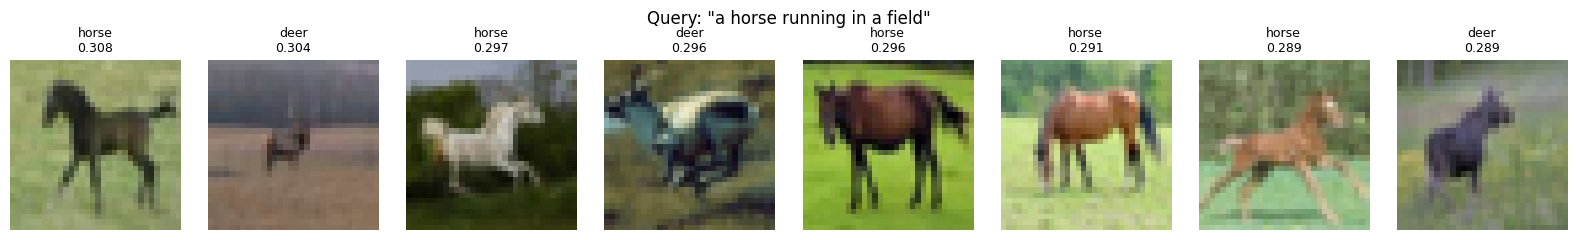

In [14]:
def search(query, k=8):
    q = encode_texts([query])
    scores = (test_feats @ q.T).squeeze(1)
    top = scores.topk(k)
    fig, axes = plt.subplots(1, k, figsize=(2 * k, 2.4))
    for ax, s, i in zip(axes, top.values.cpu(), top.indices.cpu()):
        ax.imshow(test_imgs[i]); ax.axis("off")
        ax.set_title(f"{CLASSES[test_labels[i]]}\n{s:.3f}", fontsize=9)
    fig.suptitle(f'Query: "{query}"'); plt.tight_layout(); plt.show()

search("a red sports car")
search("a ship on the open sea")
search("a horse running in a field")

## 8. Your own dataset

Put images in a class-per-folder layout:

```
my_dataset/
  class_a/  img1.jpg img2.jpg ...
  class_b/  ...
```

Either upload a zip (`my_dataset.zip`) to `/content`, or mount Google Drive and point `DATA_DIR`
at the folder. Folder names become class names for zero-shot, so make them readable
(e.g. `hole_in_fabric`, `stain`). Underscores are replaced with spaces.

In [ ]:
# Option A: mount Google Drive
# from google.colab import drive; drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/my_dataset"

# Option B: upload my_dataset.zip to /content and unzip
# !unzip -q /content/my_dataset.zip -d /content

DATA_DIR = "/content/my_dataset"

In [ ]:
from glob import glob
from sklearn.model_selection import StratifiedKFold

EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

if not os.path.isdir(DATA_DIR):
    print(f"{DATA_DIR} not found. Set DATA_DIR above and re-run.")
else:
    class_dirs = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
    my_classes = [d.replace("_", " ") for d in class_dirs]
    paths, ys = [], []
    for ci, d in enumerate(class_dirs):
        for p in sorted(glob(os.path.join(DATA_DIR, d, "*"))):
            if p.lower().endswith(EXTS):
                paths.append(p); ys.append(ci)
    ys = np.array(ys)
    print(f"{len(paths)} images, {len(my_classes)} classes:", dict(zip(my_classes, np.bincount(ys))))

    my_feats = encode_images([load_image(p) for p in paths])

    # Zero-shot with folder names (edit TEMPLATES or my_classes for domain-specific prompts)
    zs_acc, _ = zeroshot_accuracy(my_feats, ys, my_classes)
    print(f"Zero-shot accuracy: {zs_acc * 100:.2f}%")

    # Linear probe with 5-fold cross-validation (needs >= 5 images per class)
    if np.bincount(ys).min() >= 5:
        X = my_feats.cpu().numpy()
        accs = []
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, ys):
            clf = LogisticRegression(C=0.316, max_iter=2000).fit(X[tr], ys[tr])
            accs.append(clf.score(X[te], ys[te]))
        print(f"Linear probe (5-fold CV): {np.mean(accs) * 100:.2f}% +/- {np.std(accs) * 100:.2f}")
    else:
        print("Need at least 5 images per class for the cross-validated linear probe.")

## 9. Save embeddings (optional)

Handy if you want to reuse features without re-encoding.

In [ ]:
torch.save({"model": MODEL_ID, "cifar_test_feats": test_feats.cpu(),
            "cifar_test_labels": torch.tensor(test_labels)}, "/content/clip_features.pt")
print("Saved /content/clip_features.pt")

## Ideas to try next

- Swap `MODEL_ID` to `openai/clip-vit-large-patch14` and compare zero-shot and few-shot curves.
- Write domain-specific prompt templates (e.g. `"a macro photo of {} on fabric."`) and watch zero-shot accuracy on your dataset.
- Try `open_clip` checkpoints (LAION / DataComp / SigLIP) for stronger backbones: `pip install open_clip_torch`.
- Replace the linear probe with Tip-Adapter or CoOp-style prompt tuning for better few-shot results.